# TP : estimer la qualité d'une traduction (QE) avec un MLP sur des embeddings

**Objectif.** Prédire, *sans traduction de référence*, la qualité d'une traduction automatique à partir de la phrase source et de la sortie du système. C'est la tâche d'*estimation de la qualité* (*quality estimation*, QE).

**Idée.** On ne réentraîne pas de grand modèle. Un encodeur multilingue pré-entraîné (LaBSE) transforme chaque phrase en vecteur, puis un petit réseau, que vous entraînez ici, prédit le score de qualité. C'est une version miniature de ce que fait COMET.

**Ce que vous allez faire**

1. charger des traductions annotées par des humains (WMT20 MLQE, tâche 1) ;
2. calculer les embeddings de la source et de la traduction ;
3. construire des caractéristiques à partir de ces deux vecteurs ;
4. comparer une ligne de base (cosinus), un **modèle linéaire** et un **MLP** ;
5. mesurer l'apport de chaque famille de caractéristiques (ablation) ;
6. analyser les erreurs.

Un GPU accélère le calcul des embeddings, mais n'est pas indispensable.

In [5]:
%pip install -q datasets sentence-transformers scipy pandas matplotlib

In [6]:
import os, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("appareil :", device)

appareil : cpu


## 1. Les données

Le corpus **WMT20 MLQE (tâche 1)** contient, pour chaque phrase source, la sortie d'un système de traduction neuronale et un **score humain** : une évaluation directe (*direct assessment*, DA) de 0 à 100, moyennée sur plusieurs annotateurs, puis standardisée (*z-score*) pour compenser les différences entre annotateurs. C'est ce score standardisé (`z_mean`) que nous allons prédire.

Nous utilisons par défaut la paire **roumain → anglais**. Vous pouvez changer `PAIR` plus tard.

In [8]:
from datasets import load_dataset

PAIR = "ro-en"        # essayez aussi "et-en", "ne-en", "si-en", "en-de", "en-zh" etc.
SRC_LANG, TGT_LANG = PAIR.split("-")

raw = load_dataset("wmt/wmt20_mlqe_task1", PAIR)

def to_df(split):
    d = raw[split]
    df = pd.DataFrame({
        "src": [ex[SRC_LANG] for ex in d["translation"]],   # phrase source
        "mt":  [ex[TGT_LANG] for ex in d["translation"]],   # sortie du système
        "y":   d["z_mean"],                                  # score humain standardisé
    })
    return df[df["y"] > -9999].reset_index(drop=True)       # -10000 = score absent

train_df, val_df, test_df = to_df("train"), to_df("validation"), to_df("test")
print({"train": len(train_df), "val": len(val_df), "test": len(test_df)})

{'train': 7000, 'val': 1000, 'test': 1000}


Regardons quelques exemples et la distribution des scores.

SRC : Împreună, industrializarea, urbanizarea și Perturbarea din 1843 au subminat tradiția școlilor parohiale.
MT  : Together, industrialisation, urbanisation and disruption of 1843 undermined the tradition of paralytic schools.
score (z) : -0.94

SRC : Principalul obiectiv al germanilor era distrugerea RAF Fighter Command.
MT  : The German main objective was to destroy RAF Fighter Command.
score (z) : 0.87

SRC : Obiceiurile calendaristice se caracterizează prin manifestări mai ample, îndeosebi în perioada sărbătorilor de iarnă.
MT  : The calendar stubles are characterised by broader manifestations, especially during winter festivals.
score (z) : -0.38



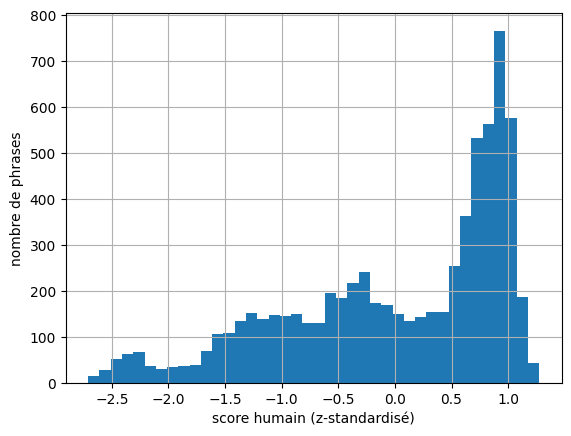

In [9]:
for _, r in train_df.sample(3, random_state=0).iterrows():
    print(f"SRC : {r.src}\nMT  : {r.mt}\nscore (z) : {r.y:.2f}\n")

train_df.y.hist(bins=40)
plt.xlabel("score humain (z-standardisé)"); plt.ylabel("nombre de phrases")
plt.show()

## 2. Les embeddings

**LaBSE** est un encodeur multilingue entraîné à rapprocher une phrase et sa traduction. Il reste **gelé** (aucun de ses paramètres n'est modifié). On calcule les embeddings une seule fois et on les enregistre : tout le reste du TP travaille sur de simples matrices NumPy, donc il est rapide.

Les vecteurs sont normalisés (norme 1) : le produit scalaire de deux vecteurs est alors leur cosinus.

In [10]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("sentence-transformers/LaBSE", device=device)
DIM = encoder.get_sentence_embedding_dimension()

def embed(texts, name):
    path = f"emb_{PAIR}_{name}.npy"
    if os.path.exists(path):
        return np.load(path)
    if len(texts) == 0:
        return np.zeros((0, DIM), dtype=np.float32)
    E = encoder.encode(texts, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.save(path, E)
    return E

emb = {}
for split, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    emb[split] = (embed(df.src.tolist(), f"{split}_src"),
                  embed(df.mt.tolist(),  f"{split}_mt"))
print("dimension d'un embedding :", DIM)

modules.json:   0%|          | 0.00/461 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.02k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

... (14 outputs left out)

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

dimension d'un embedding : 768


## 3. Les caractéristiques

Pour une paire (source, traduction), notons $u$ l'embedding de la source et $v$ celui de la traduction. On forme le vecteur de caractéristiques

$$x = [\, u \;;\; v \;;\; |u - v| \;;\; u \odot v \,]$$

où $|u-v|$ est la différence en valeur absolue et $u \odot v$ le produit terme à terme. Les deux derniers blocs mesurent **à quel point** $u$ et $v$ se ressemblent, dimension par dimension. Le modèle prédit ensuite un score $\hat{y} = f(x)$.

In [11]:
BLOCKS = {
    "u":     lambda u, v: u,
    "v":     lambda u, v: v,
    "|u-v|": lambda u, v: np.abs(u - v),
    "u*v":   lambda u, v: u * v,
}
ALL = ("u", "v", "|u-v|", "u*v")

def features(split, blocks=ALL):
    u, v = emb[split]
    return np.concatenate([BLOCKS[b](u, v) for b in blocks], axis=1).astype(np.float32)

y = {"train": train_df.y.values.astype(np.float32),
     "val":   val_df.y.values.astype(np.float32),
     "test":  test_df.y.values.astype(np.float32)}

X = features("train")
assert X.shape == (len(train_df), 4 * DIM)
print("matrice d'entraînement :", X.shape)

matrice d'entraînement : (7000, 3072)


## 4. Ligne de base : le cosinus

Sans aucun apprentissage, on peut déjà utiliser la similarité cosinus entre la source et la traduction comme score de qualité. On évalue par la corrélation avec les scores humains (Pearson pour la variation des scores, et Spearman pour les rangs).

In [12]:
def corr(pred, gold):
    return pearsonr(pred, gold)[0], spearmanr(pred, gold)[0]

for split in ("val", "test"):
    if len(y[split]) > 1:
        u, v = emb[split]
        cos = (u * v).sum(axis=1)       # vecteurs normalisés : produit scalaire = cosinus
        p, s = corr(cos, y[split])
        print(f"{split:5s}  cosinus   Pearson = {p:.3f}   Spearman = {s:.3f}")

val    cosinus   Pearson = 0.678   Spearman = 0.567
test   cosinus   Pearson = 0.712   Spearman = 0.584


## 5. Deux modèles : linéaire et MLP

- **Modèle linéaire** : $\hat{y} = w^\top x + b$. C'est le score d'un modèle log-linéaire, sans le softmax puisqu'on prédit un nombre et non une distribution.
- **MLP** : $h = \mathrm{ReLU}(W_1 x + b_1)$, puis $\hat{y} = w_2^\top h + b_2$. Une couche cachée de 256 unités, avec du *dropout* pour limiter le surapprentissage.

Les deux sont entraînés avec la même procédure : perte quadratique (MSE), optimiseur AdamW, et **arrêt anticipé** : on garde les paramètres de l'époque où la corrélation sur la validation est la meilleure. Seule la couche cachée avec sa non-linéarité les distingue.

In [13]:
EPOCHS = 60

def make_linear(d):
    return nn.Linear(d, 1)

def make_mlp(d, hidden=256, p=0.3):
    return nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(p), nn.Linear(hidden, 1))

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.from_numpy(X).to(device)).squeeze(1).cpu().numpy()

def train(model, Xtr, ytr, Xva, yva, epochs=None, lr=1e-3, wd=1e-4, bs=64):
    epochs = epochs or EPOCHS
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.MSELoss()
    Xt, yt = torch.from_numpy(Xtr).to(device), torch.from_numpy(ytr).to(device)
    best, hist = -np.inf, []
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt), device=device)
        total = 0.0
        for i in range(0, len(Xt), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]).squeeze(1), yt[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        r = pearsonr(predict(model, Xva), yva)[0]
        hist.append((total / len(Xt), r))
        if r > best:
            best = r
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, hist

## 6. Expérience 1 : linéaire contre MLP

On répète chaque entraînement avec trois graines aléatoires différentes et on rapporte la moyenne et l'écart-type de la corrélation de Pearson.

In [14]:
def run(kind, blocks=ALL, seeds=(0, 1, 2), **kw):
    Xtr, Xva, Xte = (features(s, blocks) for s in ("train", "val", "test"))
    va, te = [], []
    for s in seeds:
        torch.manual_seed(s)
        model = make_linear(Xtr.shape[1]) if kind == "linéaire" else make_mlp(Xtr.shape[1])
        model, _ = train(model, Xtr, y["train"], Xva, y["val"], **kw)
        va.append(pearsonr(predict(model, Xva), y["val"])[0])
        if len(Xte) > 1:
            te.append(pearsonr(predict(model, Xte), y["test"])[0])
    return {"modèle": kind,
            "caractéristiques": " + ".join(blocks),
            "Pearson val": f"{np.mean(va):.3f} ± {np.std(va):.3f}",
            "Pearson test": f"{np.mean(te):.3f} ± {np.std(te):.3f}" if te else "n/a"}

results = pd.DataFrame([run("linéaire"), run("MLP")])
display(results)

,modèle,caractéristiques,Pearson val,Pearson test
0,linéaire,u + v + |u-v| + u*v,0.819 ± 0.000,0.829 ± 0.000
1,MLP,u + v + |u-v| + u*v,0.832 ± 0.001,0.839 ± 0.002


## 7. Les courbes d'apprentissage

Une bonne façon de voir le surapprentissage : la perte d'entraînement continue de baisser, alors que la corrélation sur la validation plafonne puis redescend.

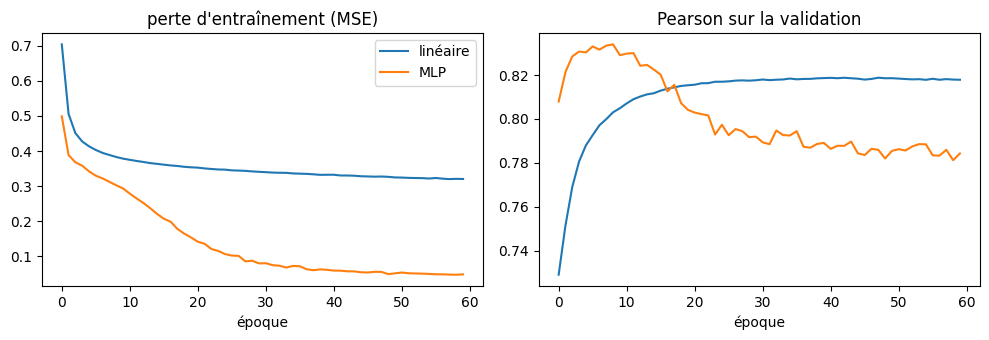

In [15]:
Xtr, Xva = features("train"), features("val")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for kind, maker in [("linéaire", make_linear), ("MLP", make_mlp)]:
    torch.manual_seed(0)
    _, hist = train(maker(Xtr.shape[1]), Xtr, y["train"], Xva, y["val"])
    axes[0].plot([h[0] for h in hist], label=kind)
    axes[1].plot([h[1] for h in hist], label=kind)
axes[0].set(title="perte d'entraînement (MSE)", xlabel="époque")
axes[1].set(title="Pearson sur la validation", xlabel="époque")
axes[0].legend(); plt.tight_layout(); plt.show()

## 8. Expérience 2 : ablation des caractéristiques

Quelles familles de caractéristiques apportent de l'information ? On refait l'expérience avec des sous-ensembles du vecteur $x$, pour le modèle linéaire et pour le MLP.

In [16]:
configs = [("u", "v"), ("|u-v|",), ("u*v",), ("|u-v|", "u*v"), ALL]
ablation = pd.DataFrame([run(kind, b) for b in configs for kind in ("linéaire", "MLP")])
display(ablation)

,modèle,caractéristiques,Pearson val,Pearson test
0,linéaire,u + v,0.704 ± 0.001,0.726 ± 0.000
1,MLP,u + v,0.720 ± 0.002,0.730 ± 0.001
2,linéaire,|u-v|,0.792 ± 0.000,0.817 ± 0.000
3,MLP,|u-v|,0.801 ± 0.000,0.825 ± 0.001
4,linéaire,u*v,0.735 ± 0.000,0.770 ± 0.000
5,MLP,u*v,0.785 ± 0.000,0.805 ± 0.001
6,linéaire,|u-v| + u*v,0.798 ± 0.000,0.820 ± 0.000
7,MLP,|u-v| + u*v,0.809 ± 0.000,0.826 ± 0.001
8,linéaire,u + v + |u-v| + u*v,0.819 ± 0.000,0.829 ± 0.000
9,MLP,u + v + |u-v| + u*v,0.832 ± 0.001,0.839 ± 0.002


## 9. Analyse des erreurs

On entraîne un dernier MLP sur toutes les caractéristiques, puis on regarde : le nuage de points entre scores prédits et scores humains, la corrélation selon la longueur de la traduction, et les cinq plus grosses erreurs.

évaluation sur « test » : Pearson = 0.836



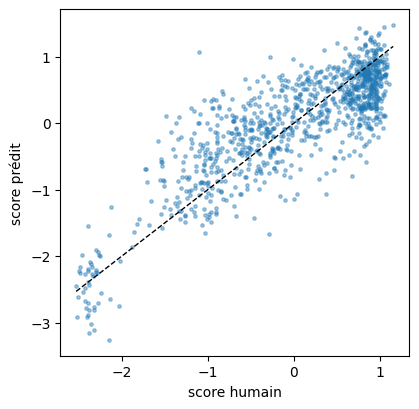

Corrélation selon la longueur de la traduction (en mots) :
  (4.999, 12.0] n =  334   Pearson = 0.801
  (12.0, 17.0] n =  341   Pearson = 0.822
  (17.0, 46.0] n =  325   Pearson = 0.867

Les cinq plus grosses erreurs :

SRC : Ovidiu Drimba, Istoria culturii și a civilizației, vol.
MT  : Ovidium Drimba, Istoria culture and civilisation, vol.
humain = -1.10   prédit = 1.07

SRC : Comitatele Maramureș, Satmar, Crasna, Solnocul Mijlociu, Bihor, Zarand, Arad, Timiș și Caraș făceau parte din Regatul Ungar.
MT  : The Committees of Maramureș, Satmar, Crasna, Middle Solnoc, Bihor, Zarand, Arad, Timiș and Carez formed part of the United Kingdom.
humain = -1.48   prédit = 0.10

SRC : Pe de altă parte, Prince of Wales și Repulse au fost singurele cuirasate aliate moderne rapide scufundate în tot războiul.
MT  : On the other hand, Prince of Wales and Reface were the only cuirasites, which were rapidly submerged in the war.
humain = 0.68   prédit = -0.79

SRC : Totul este o constatare lucidă sau o v

In [17]:
Xtr, Xva, Xte = (features(s) for s in ("train", "val", "test"))
torch.manual_seed(0)
final, _ = train(make_mlp(Xtr.shape[1]), Xtr, y["train"], Xva, y["val"])

split = "test" if len(Xte) > 1 else "val"
df_eval = (test_df if split == "test" else val_df).copy()
df_eval["pred"] = predict(final, Xte if split == "test" else Xva)
df_eval["err"] = (df_eval.pred - df_eval.y).abs()
print(f"évaluation sur « {split} » : Pearson = {pearsonr(df_eval.pred, df_eval.y)[0]:.3f}\n")

plt.figure(figsize=(4.5, 4.5))
plt.scatter(df_eval.y, df_eval.pred, s=6, alpha=0.4)
lim = [df_eval.y.min(), df_eval.y.max()]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("score humain"); plt.ylabel("score prédit")
plt.show()

df_eval["longueur"] = df_eval.mt.str.split().str.len()
df_eval["tranche"] = pd.qcut(df_eval.longueur, 3, duplicates="drop")
print("Corrélation selon la longueur de la traduction (en mots) :")
for tr, g in df_eval.groupby("tranche", observed=True):
    print(f"  {str(tr):12s} n = {len(g):4d}   Pearson = {pearsonr(g.pred, g.y)[0]:.3f}")

print("\nLes cinq plus grosses erreurs :")
for _, r in df_eval.nlargest(5, "err").iterrows():
    print(f"\nSRC : {r.src}\nMT  : {r.mt}\nhumain = {r.y:.2f}   prédit = {r.pred:.2f}")

## 10. Questions d'analyse

Répondez par écrit, en vous appuyant sur vos résultats.

1. Comparez le cosinus, le modèle linéaire et le MLP. L'apprentissage apporte-t-il beaucoup par rapport à la ligne de base ? Pourquoi cet écart est-il grand ou petit ici ?
2. Un modèle linéaire appliqué à $[u ; v]$ calcule une somme $f(u) + g(v)$. Pourquoi ne peut-il pas, dans ce cas, comparer $u$ et $v$ ? Quels blocs de caractéristiques lui donnent cette capacité ? Vérifiez avec votre tableau d'ablation.
3. Observez les courbes de la section 7. Lequel des deux modèles surapprend le plus ? Citez trois moyens de limiter ce phénomène, et dites lesquels le TP utilise déjà.
4. Relisez les cinq plus grosses erreurs. Distinguez les fautes de **fidélité** au sens de la source et les défauts de **fluidité** de la traduction. LaBSE est entraîné à rapprocher une phrase et sa traduction : lequel des deux défauts capte-t-il le mieux ?
5. Changez `PAIR` (par exemple `"et-en"`) et relancez le TP. Quelle paire est la plus facile ? Quelles explications pouvez-vous proposer ?
6. Où se trouve le « log-linéaire » dans ce TP ? Qu'est-ce qui change par rapport à un modèle de langue log-linéaire (sortie, fonction de perte) ?

## Pour aller plus loin

- Remplacez LaBSE par un autre encodeur multilingue (par exemple un modèle de la famille XLM-R ou E5) et comparez.
- Ajoutez des caractéristiques simples : longueur de la source, longueur de la traduction, rapport des deux.
- Faites varier la taille de la couche cachée, le taux de *dropout* et la régularisation, avec la validation pour choisir.
- Comparez avec un modèle de QE publié (par exemple COMET-Kiwi, qui demande d'accepter une licence sur Hugging Face).
- Réfléchissez au cas des langues sans données annotées : comment évalueriez-vous un système de QE pour le yiddish ou le pendjabi ?